### **0. Environment Setup**

In [1]:
#Import Libs
import sklearn
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler

In [2]:
#Define Colors Palette and Standards for Illustrations
RED, DARK, GRAY, LIGHT, SOFT = "#CD2027", "#404040", "#7F7F7F", "#D9D9D9", "#E9A0A3"

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.rcParams.update({
    "figure.figsize": (7.5, 4.2),
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titleweight": "bold",
    "axes.prop_cycle": cycler(color=[RED, DARK, SOFT, GRAY]),
})
pd.set_option("display.precision", 3)
pd.set_option("display.width", 120)

In [3]:
#Helper Functions: Evaluation Reports ( Confusion Matrix, Metrics, ROC and Precision-Recall )
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, log_loss, matthews_corrcoef,
                             confusion_matrix, roc_curve, precision_recall_curve)

def plot_confusion(cm, labels, ax, title="Confusion matrix"):
    ax.imshow(cm, cmap="Reds"); ax.grid(False)
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=45 if len(labels) > 4 else 0, ha="right" if len(labels) > 4 else "center")
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=10 if len(labels) > 4 else 13,
                    color="white" if cm[i, j] > cm.max() / 2 else DARK)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title)

def report_binary(y_true, y_pred, y_score, name="model", labels=("negative", "positive"), plot=True):
    """Confusion matrix, ROC and Precision-Recall curves + a Series with the main metrics (positive class = 1)."""
    y_true, y_pred, y_score = np.asarray(y_true), np.asarray(y_pred), np.asarray(y_score)
    metrics = {"accuracy": accuracy_score(y_true, y_pred), "balanced acc.": balanced_accuracy_score(y_true, y_pred),
               "precision": precision_score(y_true, y_pred, zero_division=0), "recall": recall_score(y_true, y_pred),
               "F1": f1_score(y_true, y_pred), "MCC": matthews_corrcoef(y_true, y_pred),
               "ROC AUC": roc_auc_score(y_true, y_score), "PR AUC": average_precision_score(y_true, y_score)}
    if plot:
        fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
        plot_confusion(confusion_matrix(y_true, y_pred), list(labels), axes[0], f"Confusion matrix – {name}")
        fpr, tpr, _ = roc_curve(y_true, y_score)
        axes[1].plot(fpr, tpr, color=RED, lw=2.4, label=f"AUC = {metrics['ROC AUC']:.3f}"); axes[1].plot([0, 1], [0, 1], color=GRAY, ls="--")
        axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate"); axes[1].set_title("ROC curve"); axes[1].legend(loc="lower right")
        p, r, _ = precision_recall_curve(y_true, y_score)
        axes[2].plot(r, p, color=DARK, lw=2.4, label=f"AP = {metrics['PR AUC']:.3f}"); axes[2].axhline(y_true.mean(), color=GRAY, ls="--")
        axes[2].set_xlabel("recall"); axes[2].set_ylabel("precision"); axes[2].set_title("Precision–Recall curve"); axes[2].legend(loc="lower left")
        plt.tight_layout(); plt.show()
    return pd.Series(metrics, name=name)

def report_multiclass(y_true, y_pred, y_proba, labels, name="model", plot=True):
    """Confusion matrix, one-vs-rest ROC curves and per-class F1 + a Series with the main metrics."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    k = len(labels)
    metrics = {"accuracy": accuracy_score(y_true, y_pred), "balanced acc.": balanced_accuracy_score(y_true, y_pred),
               "macro precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
               "macro recall": recall_score(y_true, y_pred, average="macro"), "macro F1": f1_score(y_true, y_pred, average="macro"),
               "MCC": matthews_corrcoef(y_true, y_pred), "ROC AUC (ovr)": roc_auc_score(y_true, y_proba, multi_class="ovr"),
               "log loss": log_loss(y_true, y_proba, labels=list(range(k)))}
    if plot:
        fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1.1, 1, 1]})
        plot_confusion(confusion_matrix(y_true, y_pred, labels=list(range(k))), list(labels), axes[0], f"Confusion matrix – {name}")
        cmap = plt.get_cmap("tab10")
        for c in range(k):
            fpr, tpr, _ = roc_curve((y_true == c).astype(int), y_proba[:, c])
            axes[1].plot(fpr, tpr, color=cmap(c), lw=1.6, label=f"{labels[c]}")
        axes[1].plot([0, 1], [0, 1], color=GRAY, ls="--"); axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate")
        axes[1].set_title(f"ROC one-vs-rest (macro AUC = {metrics['ROC AUC (ovr)']:.3f})"); axes[1].legend(fontsize=7, ncol=2 if k > 5 else 1, loc="lower right")
        f1s = f1_score(y_true, y_pred, average=None)
        axes[2].bar(range(k), f1s, color=RED, width=0.65); axes[2].set_xticks(range(k)); axes[2].set_xticklabels(labels, rotation=45 if k > 4 else 0, ha="right" if k > 4 else "center")
        axes[2].set_ylim(0, 1.05); axes[2].set_ylabel("F1"); axes[2].set_title("F1 per class")
        plt.tight_layout(); plt.show()
    return pd.Series(metrics, name=name)
def annotate_heatmap(ax, mat, fmt="{:.2f}"):
    """Write the values on an imshow heat map with a readable text color."""
    mat = np.asarray(mat, dtype=float)
    lo, hi = np.nanmin(mat), np.nanmax(mat)
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            v = mat[i, j]
            ax.text(j, i, "–" if np.isnan(v) else fmt.format(v), ha="center", va="center", color="white" if (not np.isnan(v) and v > (lo + hi) / 2) else DARK)

### **1. Clustering Techniques**

**Unsupervised** grouping of similar objects. The techniques differ in what a *cluster* is:

| Technique | A cluster is… | Needs *k*? | Finds arbitrary shapes? | Handles noise? |
|---|---|---|---|---|
| **K-Means** | points around a **centroid** (spherical) | yes | no | no |
| **Hierarchical** | a branch of a **dendrogram** | cut level | depends on linkage | no |
| **DBSCAN** | a **dense** region (core points + border) | no (needs `eps`) | yes | **yes** |
| **OPTICS** | density-ordered points (many densities) | no | yes | yes |
| **GMM** | a **Gaussian** (soft assignment, EM) | yes | ellipses | no |
| **Mean Shift** | a **mode** of the density | no (bandwidth) | blobs | partly |
| **Spectral** | a connected group in a **similarity graph** | yes | yes | no |

**How to evaluate** (no single answer): **internal** metrics use only the data (silhouette, Calinski–Harabasz, Davies–Bouldin); **external** metrics compare with known labels (ARI, NMI, V-measure, purity, accuracy after matching clusters to classes).

### **2. Datasets and Evaluation Functions**

Five 2-D datasets (400 points, true labels known) with **different geometries**, and a real one (digits) later.

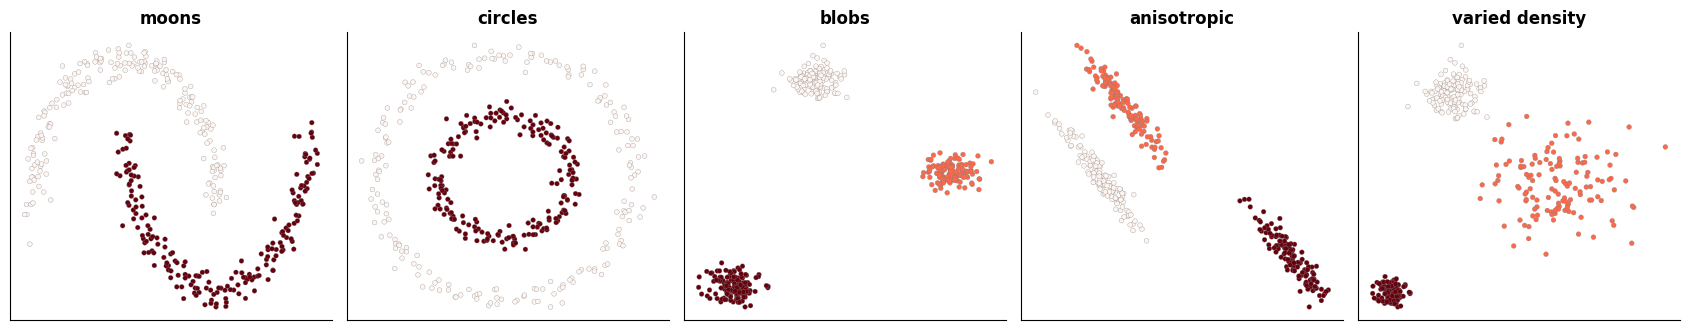

In [4]:
#Five Synthetic Datasets: Moons, Circles, Blobs, Anisotropic Blobs and Blobs with Different Densities
from sklearn.datasets import make_moons, make_circles, make_blobs
from sklearn.preprocessing import StandardScaler

n = 400
datasets = {}
datasets["moons"] = make_moons(n, noise=0.06, random_state=RANDOM_STATE)
datasets["circles"] = make_circles(n, factor=0.5, noise=0.05, random_state=RANDOM_STATE)
datasets["blobs"] = make_blobs(n, centers=3, cluster_std=0.7, random_state=RANDOM_STATE)
Xa, ya = make_blobs(n, centers=3, cluster_std=0.6, random_state=170)
datasets["anisotropic"] = (Xa @ np.array([[0.6, -0.6], [-0.4, 0.8]]), ya)
datasets["varied density"] = make_blobs(n, centers=3, cluster_std=[1.0, 2.5, 0.5], random_state=RANDOM_STATE)
datasets = {k: (StandardScaler().fit_transform(X_), y_) for k, (X_, y_) in datasets.items()}
K_TRUE = {k: len(np.unique(y_)) for k, (_, y_) in datasets.items()}

fig, axes = plt.subplots(1, 5, figsize=(17, 3.4))
for ax, (name, (X_, y_)) in zip(axes, datasets.items()):
    ax.scatter(X_[:, 0], X_[:, 1], c=y_, cmap="Reds", s=12, edgecolor=GRAY, lw=0.2); ax.set_title(name); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

In [5]:
#Evaluation Functions: Internal Metrics, External Metrics and Cluster-to-Class Matching ( Hungarian Algorithm )
from sklearn.metrics import (silhouette_score, silhouette_samples, calinski_harabasz_score, davies_bouldin_score, adjusted_rand_score, normalized_mutual_info_score,
                             v_measure_score, homogeneity_score, completeness_score, fowlkes_mallows_score)
from scipy.optimize import linear_sum_assignment

def purity(y_true, labels):
    cont = pd.crosstab(labels, y_true)
    return cont.max(axis=1).sum() / len(y_true)

def match_clusters(y_true, labels, n_classes=None):
    """Hungarian matching: relabel clusters so that they agree as much as possible with the true classes."""
    classes = np.unique(y_true)
    clusters = np.unique(labels[labels != -1])
    cont = np.array([[np.sum((y_true == c) & (labels == k)) for k in clusters] for c in classes])
    rows, cols = linear_sum_assignment(-cont)
    mapping = {clusters[j]: classes[i] for i, j in zip(rows, cols)}
    return np.array([mapping.get(l, -1) for l in labels]), mapping

def cluster_scores(X, labels, y=None):
    mask = labels != -1
    k = len(set(labels[mask]))
    out = {"clusters": k, "noise %": 100 * (~mask).mean()}
    ok = k >= 2 and mask.sum() > k
    out["silhouette"] = silhouette_score(X[mask], labels[mask]) if ok else np.nan
    out["Calinski-Harabasz"] = calinski_harabasz_score(X[mask], labels[mask]) if ok else np.nan
    out["Davies-Bouldin"] = davies_bouldin_score(X[mask], labels[mask]) if ok else np.nan
    if y is not None:
        out.update({"ARI": adjusted_rand_score(y, labels), "NMI": normalized_mutual_info_score(y, labels), "V-measure": v_measure_score(y, labels),
                    "homogeneity": homogeneity_score(y, labels), "completeness": completeness_score(y, labels),
                    "Fowlkes-Mallows": fowlkes_mallows_score(y, labels), "purity": purity(y, labels)})
    return out

import warnings
from sklearn.cluster import SpectralClustering

def spectral(X, k, n_neighbors=15):
    """Spectral clustering on a k-nearest-neighbour graph. Well-separated clusters make the graph disconnected (one component per cluster),
    which scikit-learn reports with a warning that is expected here, so only that message is silenced."""
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", message="Graph is not fully connected")
        return SpectralClustering(n_clusters=k, affinity="nearest_neighbors", n_neighbors=n_neighbors, random_state=RANDOM_STATE).fit_predict(X)

print("metrics ready: silhouette, Calinski-Harabasz, Davies-Bouldin | ARI, NMI, V-measure, homogeneity, completeness, Fowlkes-Mallows, purity")

metrics ready: silhouette, Calinski-Harabasz, Davies-Bouldin | ARI, NMI, V-measure, homogeneity, completeness, Fowlkes-Mallows, purity


### **3. K-Means**

Lloyd's algorithm alternates two steps until the assignments stop changing:

1. **Assign** each point to the nearest centroid
2. **Update** each centroid to the **mean** of its points

It minimises the **inertia** (within-cluster sum of squares) $\sum_k \sum_{x \in C_k} \lVert x - \mu_k \rVert^2$ – but only to a **local** minimum (hence several initialisations and **k-means++**).

seed 0 -> iterations: 3 | inertia (scratch): 12.5556 | inertia (scikit-learn): 12.5556 | same partition: True
seed 1 -> final inertia 240.27: a poor LOCAL minimum (two blobs merged), because K-Means depends on the initial centroids


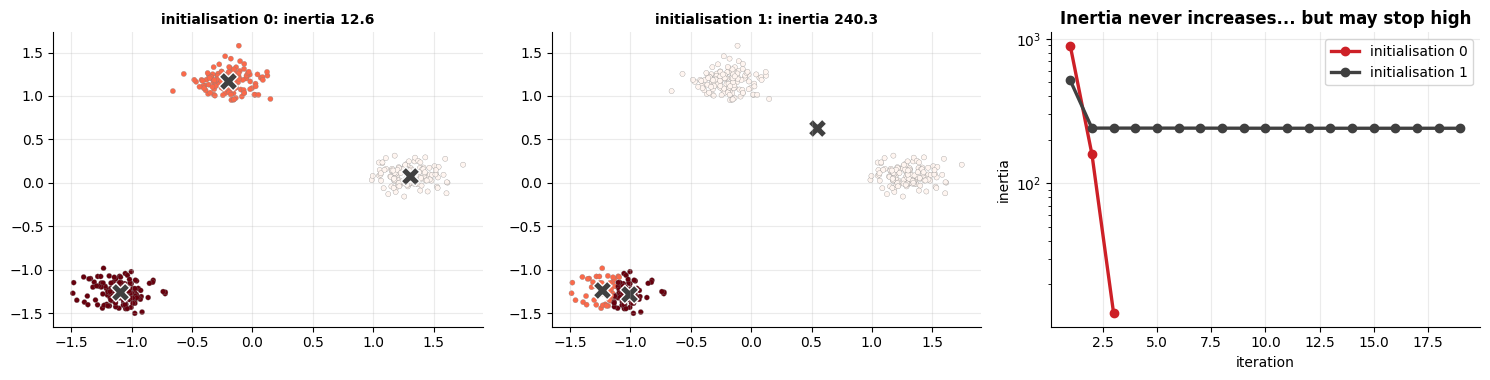

In [6]:
#K-Means from Scratch ( Lloyd's Algorithm ) and Check Against scikit-learn ( Same Initial Centroids )
from sklearn.cluster import KMeans

def kmeans_scratch(X, init_centers, max_iter=100):
    centers, history = init_centers.copy(), []
    for _ in range(max_iter):
        d = ((X[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)
        labels = d.argmin(axis=1)                                                           # assignment step
        history.append(d[np.arange(len(X)), labels].sum())                                   # inertia
        new = np.array([X[labels == k].mean(axis=0) if (labels == k).any() else centers[k] for k in range(len(centers))])
        if np.allclose(new, centers):
            break
        centers = new                                                                       # update step
    return labels, centers, history

Xb, yb_ = datasets["blobs"]
init_centers = lambda seed: Xb[np.random.default_rng(seed).choice(len(Xb), 3, replace=False)]
runs = {seed: kmeans_scratch(Xb, init_centers(seed)) for seed in (0, 1)}                  # seed 0: a good start · seed 1: a bad start
lab_s, cen_s, hist_s = runs[0]
km_ref = KMeans(n_clusters=3, init=init_centers(0), n_init=1, algorithm="lloyd", tol=0, random_state=0).fit(Xb)
print(f"seed 0 -> iterations: {len(hist_s)} | inertia (scratch): {hist_s[-1]:.4f} | inertia (scikit-learn): {km_ref.inertia_:.4f} | same partition: {adjusted_rand_score(lab_s, km_ref.labels_) == 1.0}")
print(f"seed 1 -> final inertia {runs[1][2][-1]:.2f}: a poor LOCAL minimum (two blobs merged), because K-Means depends on the initial centroids")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.9))
for ax, seed in zip(axes[:2], (0, 1)):
    l, c_, h_ = runs[seed]
    ax.scatter(Xb[:, 0], Xb[:, 1], c=l, cmap="Reds", s=14, edgecolor=GRAY, lw=0.2); ax.scatter(c_[:, 0], c_[:, 1], marker="X", s=180, color=DARK, edgecolor="white")
    ax.set_title(f"initialisation {seed}: inertia {h_[-1]:.1f}", fontsize=10)
for seed, color in zip((0, 1), (RED, DARK)):
    axes[2].plot(range(1, len(runs[seed][2]) + 1), runs[seed][2], marker="o", color=color, lw=2.4, label=f"initialisation {seed}")
axes[2].set_yscale("log"); axes[2].set_xlabel("iteration"); axes[2].set_ylabel("inertia"); axes[2].set_title("Inertia never increases... but may stop high"); axes[2].legend()
plt.tight_layout(); plt.show()

#### **K-Means-Specific Metrics: Choosing *k***

**Elbow** (inertia), **silhouette** (higher is better), **Calinski–Harabasz** (higher) and **Davies–Bouldin** (lower). The external **ARI** is shown only because here we know the truth.

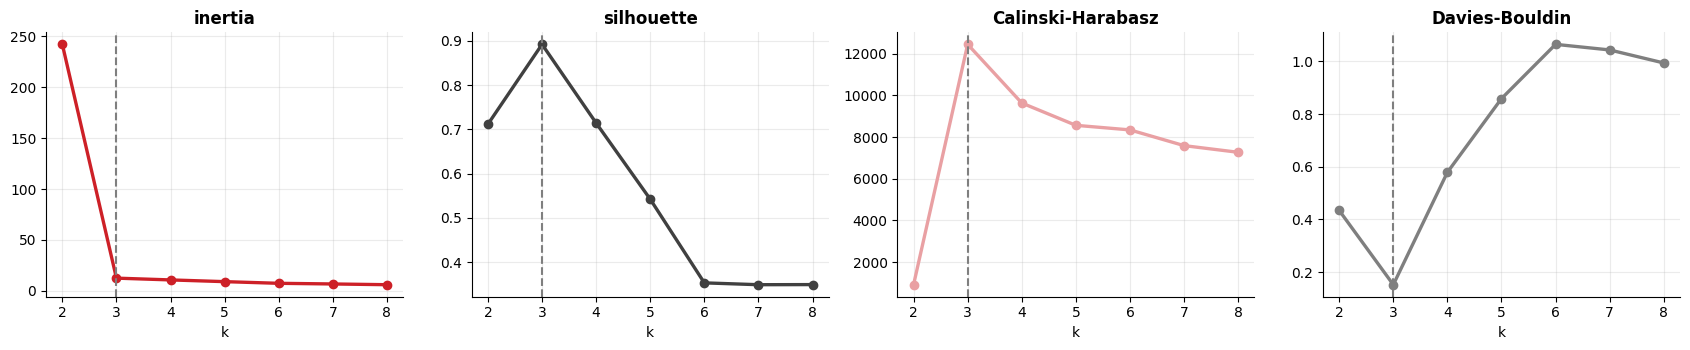

,k,inertia,silhouette,Calinski-Harabasz,Davies-Bouldin,ARI
0,2,241.909,0.712,918.200,0.434,0.569
1,3,12.556,0.892,12449.203,0.152,1.000
2,4,10.812,0.714,9635.070,0.579,0.871
3,5,9.119,0.542,8564.652,0.859,0.730
4,6,7.484,0.353,8344.797,1.065,0.581
5,7,6.845,0.349,7590.720,1.044,0.523
6,8,6.116,0.350,7271.023,0.994,0.468


In [7]:
#Choosing k on the Blobs ( 3 True Clusters ): Inertia, Silhouette, Calinski-Harabasz, Davies-Bouldin and ARI
rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Xb)
    rows.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(Xb, km.labels_), "Calinski-Harabasz": calinski_harabasz_score(Xb, km.labels_),
                 "Davies-Bouldin": davies_bouldin_score(Xb, km.labels_), "ARI": adjusted_rand_score(yb_, km.labels_)})
ksel = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
for ax, col, color in zip(axes, ["inertia", "silhouette", "Calinski-Harabasz", "Davies-Bouldin"], [RED, DARK, SOFT, GRAY]):
    ax.plot(ksel["k"], ksel[col], marker="o", color=color, lw=2.4); ax.axvline(3, color=GRAY, ls="--"); ax.set_xlabel("k"); ax.set_title(col)
plt.tight_layout(); plt.show()
ksel.round(3)

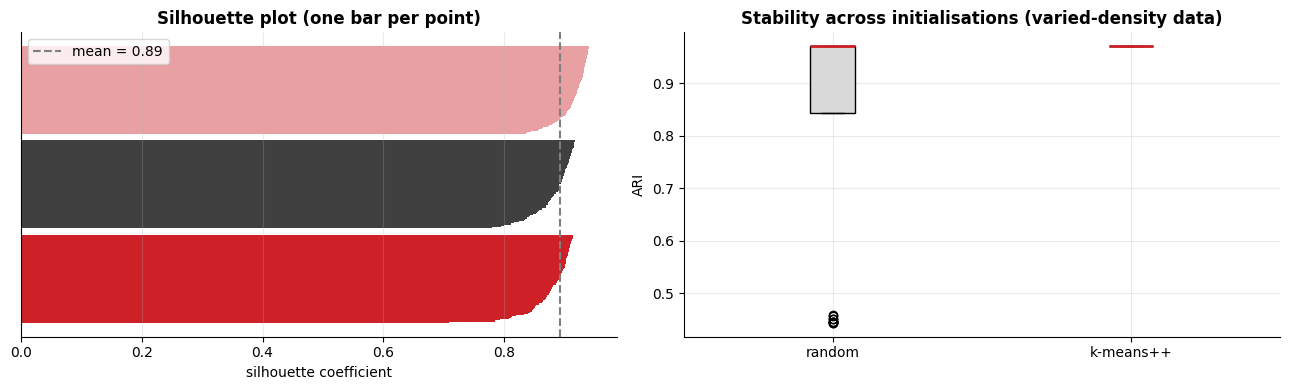

In [8]:
#Silhouette Plot ( k = 3 ) and Sensitivity to the Initialisation ( random vs k-means++, 40 Runs, 1 Initialisation Each )
km3 = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE).fit(Xb)
sil = silhouette_samples(Xb, km3.labels_)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
y_low = 0
for k in range(3):
    s_k = np.sort(sil[km3.labels_ == k]); axes[0].barh(np.arange(y_low, y_low + len(s_k)), s_k, color=[RED, DARK, SOFT][k], height=1.0); y_low += len(s_k) + 10
axes[0].axvline(sil.mean(), color=GRAY, ls="--", label=f"mean = {sil.mean():.2f}"); axes[0].set_xlabel("silhouette coefficient"); axes[0].set_yticks([]); axes[0].set_title("Silhouette plot (one bar per point)"); axes[0].legend()

Xv_, yv_ = datasets["varied density"]
ari_init = {init_: [adjusted_rand_score(yv_, KMeans(n_clusters=3, init=init_, n_init=1, random_state=s).fit_predict(Xv_)) for s in range(40)] for init_ in ("random", "k-means++")}
bp = axes[1].boxplot(list(ari_init.values()), patch_artist=True, medianprops=dict(color=RED, lw=2))
for b in bp["boxes"]:
    b.set_facecolor(LIGHT)
axes[1].set_xticks([1, 2]); axes[1].set_xticklabels(list(ari_init)); axes[1].set_ylabel("ARI"); axes[1].set_title("Stability across initialisations (varied-density data)")
plt.tight_layout(); plt.show()

### **4. Hierarchical Clustering**

**Agglomerative:** start with every point as a cluster and **merge** the two closest ones, repeatedly. The result is a **dendrogram**; cutting it at a height gives the clusters. The **linkage** defines the distance between clusters:

* **single:** nearest pair (chains → finds elongated shapes, sensitive to noise) · **complete:** farthest pair (compact) · **average:** mean of pairs · **ward:** smallest increase of variance (like K-Means)

**Specific metric:** the **cophenetic correlation** – how faithfully the dendrogram preserves the original pairwise distances.

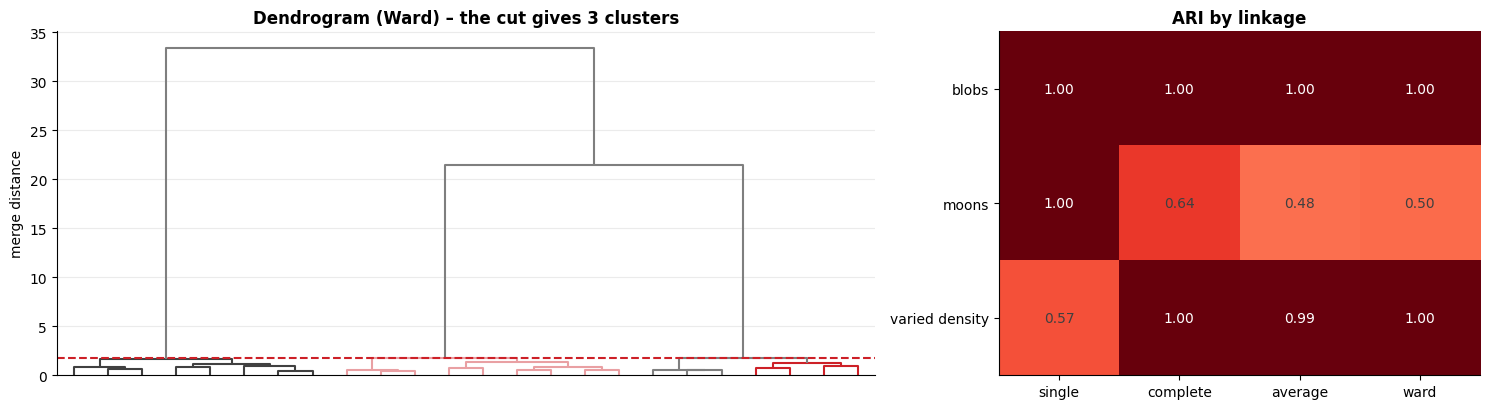

linkage,single,complete,average,ward
dataset,,,,
blobs,0.981,0.986,0.989,0.988
moons,0.564,0.741,0.740,0.723
varied density,0.836,0.826,0.942,0.937


In [9]:
#Dendrogram ( Ward, Blobs ) and Cophenetic Correlation of Each Linkage
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet, fcluster
from scipy.spatial.distance import pdist

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1.7, 1]})
Z = linkage(Xb, method="ward")
dendrogram(Z, truncate_mode="lastp", p=24, ax=axes[0], color_threshold=Z[-3, 2] * 0.99, above_threshold_color=GRAY, no_labels=True)
axes[0].axhline(Z[-3, 2] * 0.99, color=RED, ls="--"); axes[0].set_title("Dendrogram (Ward) – the cut gives 3 clusters"); axes[0].set_ylabel("merge distance")

rows = []
for name in ["moons", "blobs", "varied density"]:
    X_, y_ = datasets[name]
    for method in ["single", "complete", "average", "ward"]:
        Zm = linkage(X_, method=method)
        rows.append({"dataset": name, "linkage": method, "cophenetic corr.": cophenet(Zm, pdist(X_))[0], "ARI": adjusted_rand_score(y_, fcluster(Zm, K_TRUE[name], criterion="maxclust"))})
link = pd.DataFrame(rows)
piv = link.pivot(index="dataset", columns="linkage", values="ARI")[["single", "complete", "average", "ward"]]
im = axes[1].imshow(piv, cmap="Reds", vmin=0, vmax=1, aspect="auto"); axes[1].grid(False)
axes[1].set_xticks(range(4)); axes[1].set_xticklabels(piv.columns); axes[1].set_yticks(range(3)); axes[1].set_yticklabels(piv.index); axes[1].set_title("ARI by linkage"); annotate_heatmap(axes[1], piv.to_numpy(), "{:.2f}")
plt.tight_layout(); plt.show()
link.pivot(index="dataset", columns="linkage", values="cophenetic corr.")[["single", "complete", "average", "ward"]].round(3)

There is **no best linkage**: *single* separates the **moons** perfectly (ARI 1.00, it follows the chain) but is poor on the **varied-density** blobs (0.57), while *ward* and *complete* are the best on **compact** groups but fail on the moons (0.50 and 0.64).

### **5. DBSCAN**

Density-based: two parameters, **`eps`** (radius) and **`min_samples`**.

* **Core point:** at least `min_samples` points within `eps` (itself included) · **border point:** not core, but within `eps` of a core · **noise:** neither
* A cluster = core points **density-connected** to each other, plus their border points
* **Choosing `eps`:** sort the **k-distance** of every point; the **knee** of the curve separates the dense points from the noise

In [10]:
#DBSCAN from Scratch ( Core, Border and Noise Points ) and Check Against scikit-learn
from sklearn.cluster import DBSCAN, AgglomerativeClustering
from scipy.spatial.distance import squareform

def dbscan_scratch(X, eps, min_samples):
    dist = squareform(pdist(X))
    neighbors = [np.flatnonzero(dist[i] <= eps) for i in range(len(X))]
    core = np.array([len(nb) >= min_samples for nb in neighbors])
    labels, cluster = np.full(len(X), -1), 0
    for i in range(len(X)):
        if labels[i] != -1 or not core[i]:
            continue
        labels[i], stack = cluster, [i]
        while stack:                                                                         # expand the cluster through core points
            p = stack.pop()
            if not core[p]:
                continue
            for q in neighbors[p]:
                if labels[q] == -1:
                    labels[q] = cluster; stack.append(q)
        cluster += 1
    return labels, core

def knee_eps(X, k=5):
    """eps = knee of the sorted k-distance curve (point farthest from the straight line joining its ends)."""
    d = np.sort(np.sort(squareform(pdist(X)), axis=1)[:, k])
    p0, p1 = np.array([0, d[0]]), np.array([len(d) - 1, d[-1]])
    pts = np.c_[np.arange(len(d)), d] - p0
    line = (p1 - p0) / np.linalg.norm(p1 - p0)
    dist = np.abs(pts[:, 0] * line[1] - pts[:, 1] * line[0])
    return d[int(dist.argmax())], d

Xm, ym_ = datasets["moons"]
eps_m, kdist = knee_eps(Xm, k=5)
lab_d, core_d = dbscan_scratch(Xm, eps_m, 5)
ref = DBSCAN(eps=eps_m, min_samples=5).fit(Xm)
print(f"eps (knee of the k-distance curve) = {eps_m:.3f}")
print(f"same noise points: {np.array_equal(lab_d == -1, ref.labels_ == -1)} | same core points: {np.array_equal(core_d, np.isin(np.arange(len(Xm)), ref.core_sample_indices_))} | ARI between both partitions: {adjusted_rand_score(lab_d, ref.labels_):.3f}")

eps (knee of the k-distance curve) = 0.177
same noise points: True | same core points: True | ARI between both partitions: 1.000


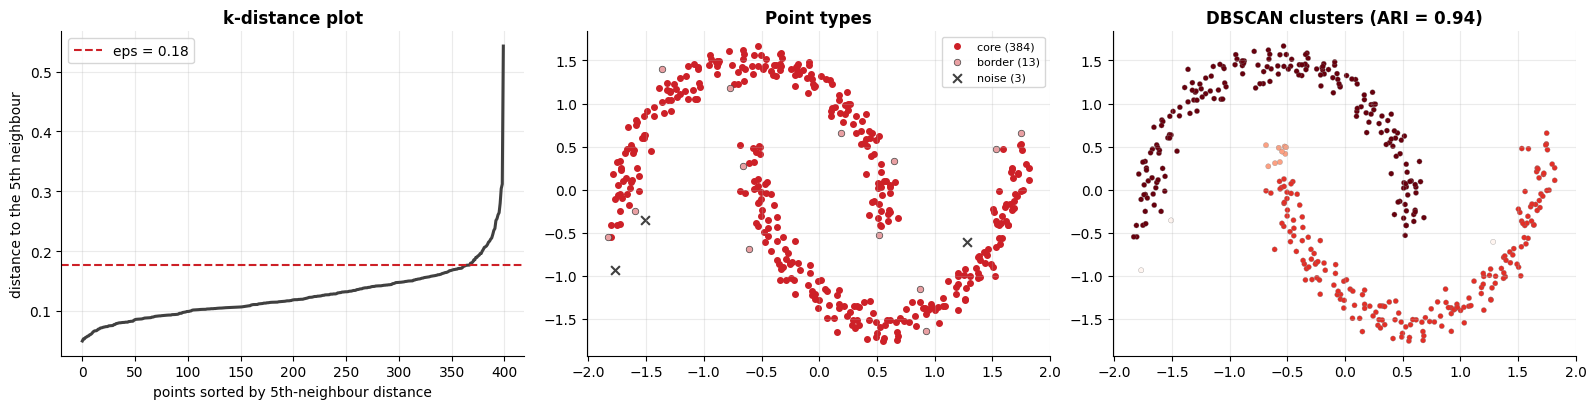

In [11]:
#DBSCAN-Specific Metrics: k-Distance Plot, Core / Border / Noise Points and the Number of Clusters
core_mask = core_d
border_mask = (lab_d != -1) & ~core_mask
noise_mask = lab_d == -1
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].plot(kdist, color=DARK, lw=2.2); axes[0].axhline(eps_m, color=RED, ls="--", label=f"eps = {eps_m:.2f}"); axes[0].set_xlabel("points sorted by 5th-neighbour distance"); axes[0].set_ylabel("distance to the 5th neighbour"); axes[0].set_title("k-distance plot"); axes[0].legend()
axes[1].scatter(*Xm[core_mask].T, s=16, color=RED, label=f"core ({core_mask.sum()})"); axes[1].scatter(*Xm[border_mask].T, s=22, color=SOFT, edgecolor=DARK, lw=0.5, label=f"border ({border_mask.sum()})")
axes[1].scatter(*Xm[noise_mask].T, s=40, marker="x", color=DARK, label=f"noise ({noise_mask.sum()})"); axes[1].set_title("Point types"); axes[1].legend(fontsize=8)
axes[2].scatter(Xm[:, 0], Xm[:, 1], c=np.where(lab_d == -1, -1, lab_d), cmap="Reds", s=14, edgecolor=GRAY, lw=0.2); axes[2].set_title(f"DBSCAN clusters (ARI = {adjusted_rand_score(ym_, lab_d):.2f})")
plt.tight_layout(); plt.show()

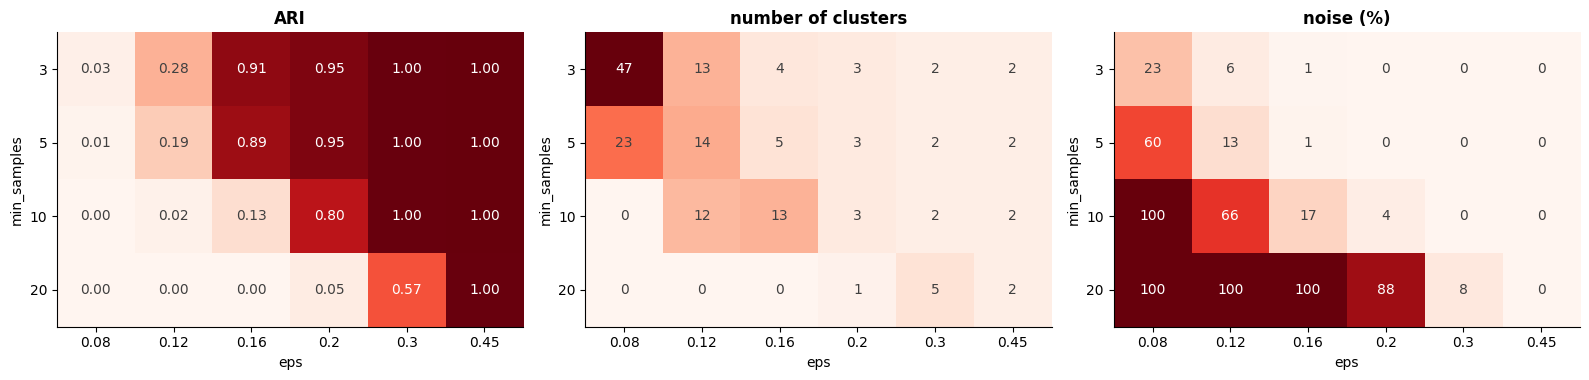

In [12]:
#Sensitivity to eps and min_samples ( Moons ): ARI, Number of Clusters and Noise Percentage
eps_grid, ms_grid = [0.08, 0.12, 0.16, 0.2, 0.3, 0.45], [3, 5, 10, 20]
ari_g, k_g, noise_g = np.zeros((4, 6)), np.zeros((4, 6)), np.zeros((4, 6))
for i, ms in enumerate(ms_grid):
    for j, e in enumerate(eps_grid):
        l = DBSCAN(eps=e, min_samples=ms).fit_predict(Xm)
        ari_g[i, j], k_g[i, j], noise_g[i, j] = adjusted_rand_score(ym_, l), len(set(l) - {-1}), 100 * (l == -1).mean()
fig, axes = plt.subplots(1, 3, figsize=(16, 3.9))
for ax, mat, title, fmt in [(axes[0], ari_g, "ARI", "{:.2f}"), (axes[1], k_g, "number of clusters", "{:.0f}"), (axes[2], noise_g, "noise (%)", "{:.0f}")]:
    ax.imshow(mat, cmap="Reds", aspect="auto"); ax.grid(False); ax.set_xticks(range(6)); ax.set_xticklabels(eps_grid); ax.set_yticks(range(4)); ax.set_yticklabels(ms_grid)
    ax.set_xlabel("eps"); ax.set_ylabel("min_samples"); ax.set_title(title); annotate_heatmap(ax, mat, fmt)
plt.tight_layout(); plt.show()

Too small an `eps` makes **everything noise**; too large **merges the moons** into one cluster. The knee of the k-distance curve gives a **good starting point**.

### **6. OPTICS**

DBSCAN uses **one** density (`eps`) for all clusters. **OPTICS** orders the points and records, for each one, the **reachability distance**; valleys of the **reachability plot** are clusters, and **different densities** appear as valleys of different depths. Clusters can then be extracted automatically (ξ method).

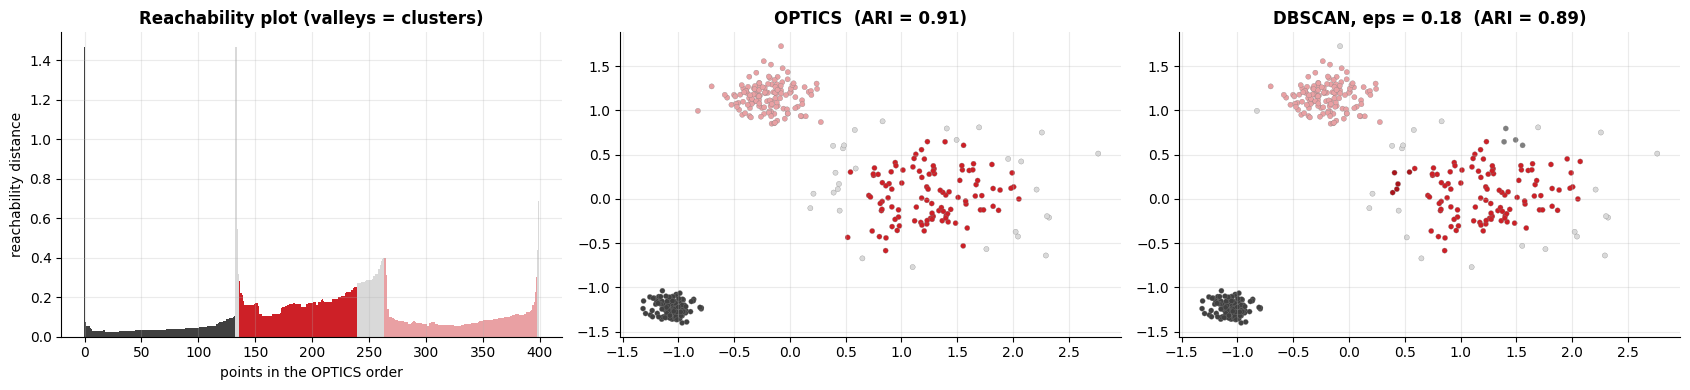

clusters found: OPTICS 3 | DBSCAN 5 | noise: OPTICS 7.2% | DBSCAN 6.0%


In [13]:
#OPTICS on the Varied-Density Blobs: Reachability Plot and Comparison with DBSCAN
from sklearn.cluster import OPTICS

Xv, yv = datasets["varied density"]
optics = OPTICS(min_samples=10, xi=0.05, min_cluster_size=0.1).fit(Xv)
eps_v, _ = knee_eps(Xv, k=5)
db_v = DBSCAN(eps=eps_v, min_samples=5).fit(Xv)
reach = optics.reachability_[optics.ordering_]
lab_o = optics.labels_[optics.ordering_]

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
cols_ = np.array([DARK, RED, SOFT, GRAY, "#A8141A"])
axes[0].bar(range(len(reach)), np.where(np.isinf(reach), np.nanmax(reach[np.isfinite(reach)]), reach), color=[cols_[l % 5] if l >= 0 else LIGHT for l in lab_o], width=1.0)
axes[0].set_xlabel("points in the OPTICS order"); axes[0].set_ylabel("reachability distance"); axes[0].set_title("Reachability plot (valleys = clusters)")
for ax, labels, title in [(axes[1], optics.labels_, f"OPTICS  (ARI = {adjusted_rand_score(yv, optics.labels_):.2f})"), (axes[2], db_v.labels_, f"DBSCAN, eps = {eps_v:.2f}  (ARI = {adjusted_rand_score(yv, db_v.labels_):.2f})")]:
    ax.scatter(Xv[:, 0], Xv[:, 1], c=[cols_[l % 5] if l >= 0 else LIGHT for l in labels], s=14, edgecolor=GRAY, lw=0.2); ax.set_title(title)
plt.tight_layout(); plt.show()
print("clusters found: OPTICS", len(set(optics.labels_) - {-1}), "| DBSCAN", len(set(db_v.labels_) - {-1}), "| noise: OPTICS", f"{(optics.labels_ == -1).mean():.1%}", "| DBSCAN", f"{(db_v.labels_ == -1).mean():.1%}")

### **7. Gaussian Mixture Model (GMM)**

The data are a **mixture of Gaussians**, $p(x) = \sum_k \pi_k \, N(x \mid \mu_k, \Sigma_k)$, fitted by **EM** (expectation–maximisation):

* **E-step:** the **responsibility** of each component for each point (a **soft** assignment)
* **M-step:** update $\pi_k$, $\mu_k$, $\Sigma_k$ using the responsibilities

**Specific metrics:** **log-likelihood**, **BIC / AIC** (to choose *k* and the covariance type) and the **uncertainty** of the assignments.

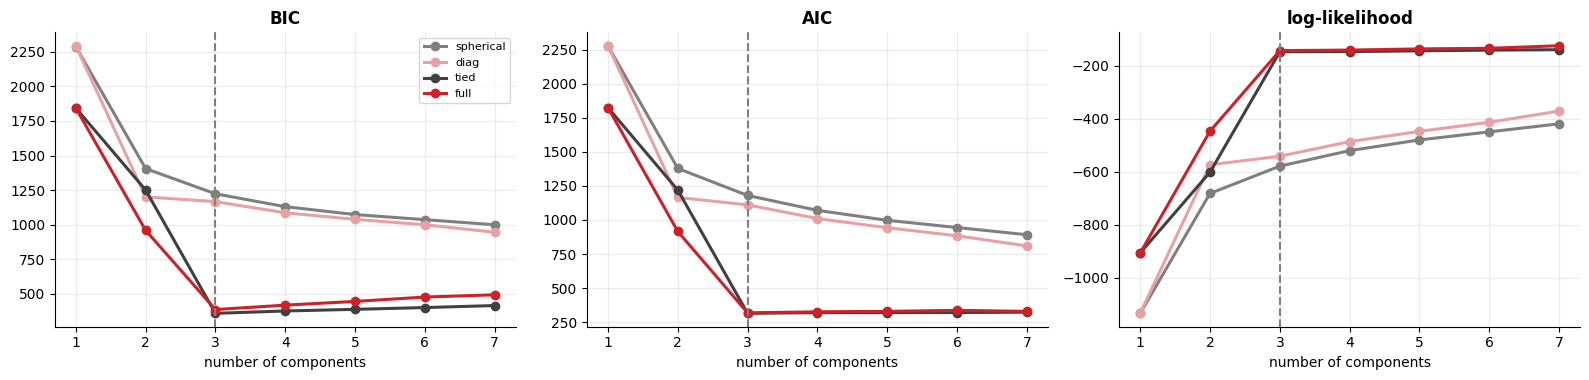

lowest BIC: tied covariance with k = 3


In [14]:
#GMM on the Anisotropic Blobs: BIC / AIC by Number of Components and Covariance Type
from sklearn.mixture import GaussianMixture

Xan, yan = datasets["anisotropic"]
rows = []
for cov in ["spherical", "diag", "tied", "full"]:
    for k in range(1, 8):
        g = GaussianMixture(n_components=k, covariance_type=cov, n_init=3, max_iter=300, random_state=RANDOM_STATE).fit(Xan)
        rows.append({"covariance": cov, "k": k, "BIC": g.bic(Xan), "AIC": g.aic(Xan), "log-likelihood": g.score(Xan) * len(Xan)})
gm = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 3, figsize=(16, 3.9))
for ax, col in zip(axes, ["BIC", "AIC", "log-likelihood"]):
    for cov, color in zip(["spherical", "diag", "tied", "full"], [GRAY, SOFT, DARK, RED]):
        sub = gm[gm["covariance"] == cov]; ax.plot(sub["k"], sub[col], marker="o", color=color, lw=2.2, label=cov)
    ax.axvline(3, color=GRAY, ls="--"); ax.set_xlabel("number of components"); ax.set_title(col)
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()
best = gm.loc[gm["BIC"].idxmin()]
print(f"lowest BIC: {best['covariance']} covariance with k = {int(best['k'])}")

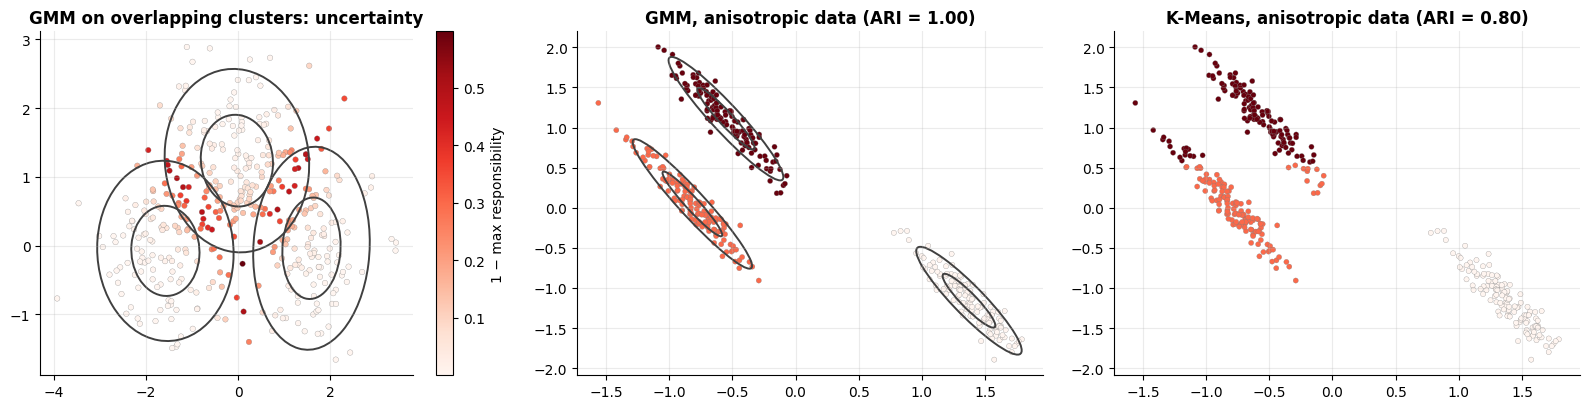

overlapping data: log-likelihood per point -2.974 | EM iterations: 4 | points with uncertainty > 0.1: 131 of 400 | mean uncertainty: 0.101 | ARI 0.59


In [15]:
#Soft Assignments ( Uncertainty on Overlapping Clusters ) and GMM vs K-Means on the Anisotropic Data
from matplotlib.patches import Ellipse

def draw_ellipses(ax, gmm_):
    for mu, cov_ in zip(gmm_.means_, gmm_.covariances_):
        vals, vecs = np.linalg.eigh(cov_); ang = np.degrees(np.arctan2(*vecs[:, 1][::-1]))
        for ns_ in (1, 2):
            ax.add_patch(Ellipse(mu, 2 * ns_ * np.sqrt(vals[1]), 2 * ns_ * np.sqrt(vals[0]), angle=ang, fill=False, edgecolor=DARK, lw=1.4))

Xov, yov = make_blobs(400, centers=[[-1.5, 0], [0, 1.3], [1.5, 0]], cluster_std=0.75, random_state=RANDOM_STATE)          # overlapping clusters
gmm_v = GaussianMixture(n_components=3, covariance_type="full", n_init=5, max_iter=300, random_state=RANDOM_STATE).fit(Xov)
unc = 1 - gmm_v.predict_proba(Xov).max(axis=1)
gmm = GaussianMixture(n_components=3, covariance_type="full", n_init=5, max_iter=300, random_state=RANDOM_STATE).fit(Xan)
km_a = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE).fit(Xan)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
sc = axes[0].scatter(Xov[:, 0], Xov[:, 1], c=unc, cmap="Reds", s=16, edgecolor=GRAY, lw=0.2); fig.colorbar(sc, ax=axes[0], label="1 − max responsibility"); draw_ellipses(axes[0], gmm_v)
axes[0].set_title("GMM on overlapping clusters: uncertainty")
axes[1].scatter(Xan[:, 0], Xan[:, 1], c=gmm.predict(Xan), cmap="Reds", s=14, edgecolor=GRAY, lw=0.2); draw_ellipses(axes[1], gmm); axes[1].set_title(f"GMM, anisotropic data (ARI = {adjusted_rand_score(yan, gmm.predict(Xan)):.2f})")
axes[2].scatter(Xan[:, 0], Xan[:, 1], c=km_a.labels_, cmap="Reds", s=14, edgecolor=GRAY, lw=0.2); axes[2].set_title(f"K-Means, anisotropic data (ARI = {adjusted_rand_score(yan, km_a.labels_):.2f})")
plt.tight_layout(); plt.show()
print(f"overlapping data: log-likelihood per point {gmm_v.score(Xov):.3f} | EM iterations: {gmm_v.n_iter_} | points with uncertainty > 0.1: {(unc > 0.1).sum()} of {len(Xov)} | mean uncertainty: {unc.mean():.3f} | ARI {adjusted_rand_score(yov, gmm_v.predict(Xov)):.2f}")

### **8. Mean Shift and Spectral Clustering**

* **Mean Shift:** every point **climbs the density** (moves to the mean of its neighbours within the **bandwidth**) until it reaches a **mode**; each mode is a cluster. No *k*, but the bandwidth matters
* **Spectral:** builds a **similarity graph** (here, k-nearest neighbours), takes the **eigenvectors of its Laplacian** and clusters them with K-Means – it separates **non-convex** shapes that K-Means cannot

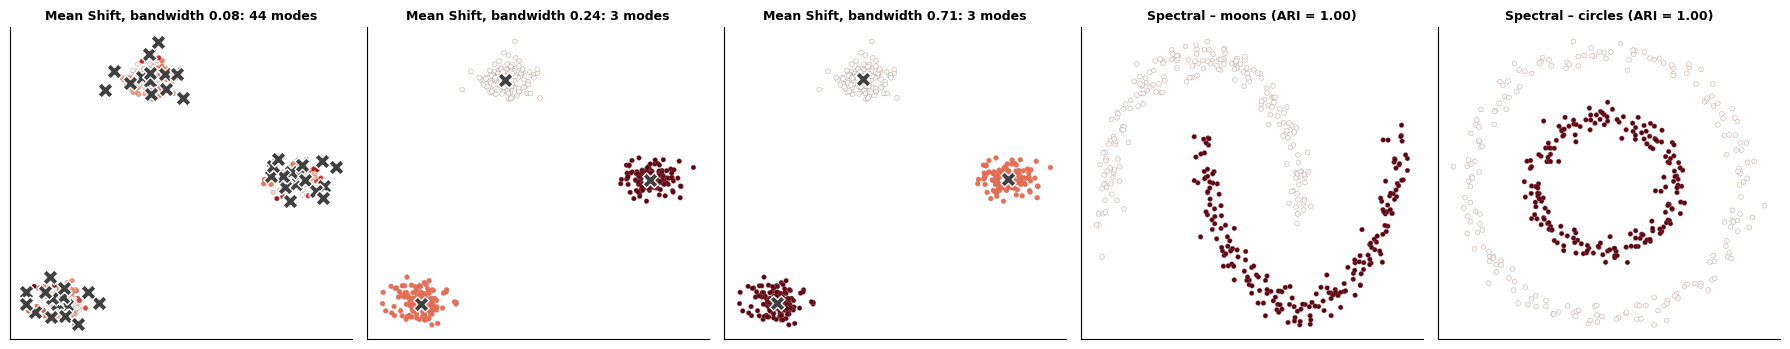

In [16]:
#Mean Shift ( Bandwidth Sweep ) and Spectral Clustering ( Moons and Circles )
from sklearn.cluster import MeanShift, estimate_bandwidth

fig, axes = plt.subplots(1, 5, figsize=(18, 3.6))
Xb_, yb2 = datasets["blobs"]
bw0 = estimate_bandwidth(Xb_, quantile=0.2)
for ax, bw in zip(axes[:3], [bw0 / 3, bw0, bw0 * 3]):
    ms = MeanShift(bandwidth=bw).fit(Xb_)
    ax.scatter(Xb_[:, 0], Xb_[:, 1], c=ms.labels_, cmap="Reds", s=12, edgecolor=GRAY, lw=0.2); ax.scatter(*ms.cluster_centers_.T, marker="X", s=120, color=DARK, edgecolor="white")
    ax.set_title(f"Mean Shift, bandwidth {bw:.2f}: {len(ms.cluster_centers_)} modes", fontsize=9)
for ax, name in zip(axes[3:], ["moons", "circles"]):
    X_, y_ = datasets[name]
    sp_labels = spectral(X_, 2)
    ax.scatter(X_[:, 0], X_[:, 1], c=sp_labels, cmap="Reds", s=12, edgecolor=GRAY, lw=0.2); ax.set_title(f"Spectral – {name} (ARI = {adjusted_rand_score(y_, sp_labels):.2f})", fontsize=9)
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

### **9. Benchmark: Every Algorithm on Every Geometry**

Same configuration everywhere: *k* = true number of clusters where needed, `eps` from the k-distance **knee**, OPTICS ξ = 0.05, Mean Shift bandwidth from a 20 % quantile.

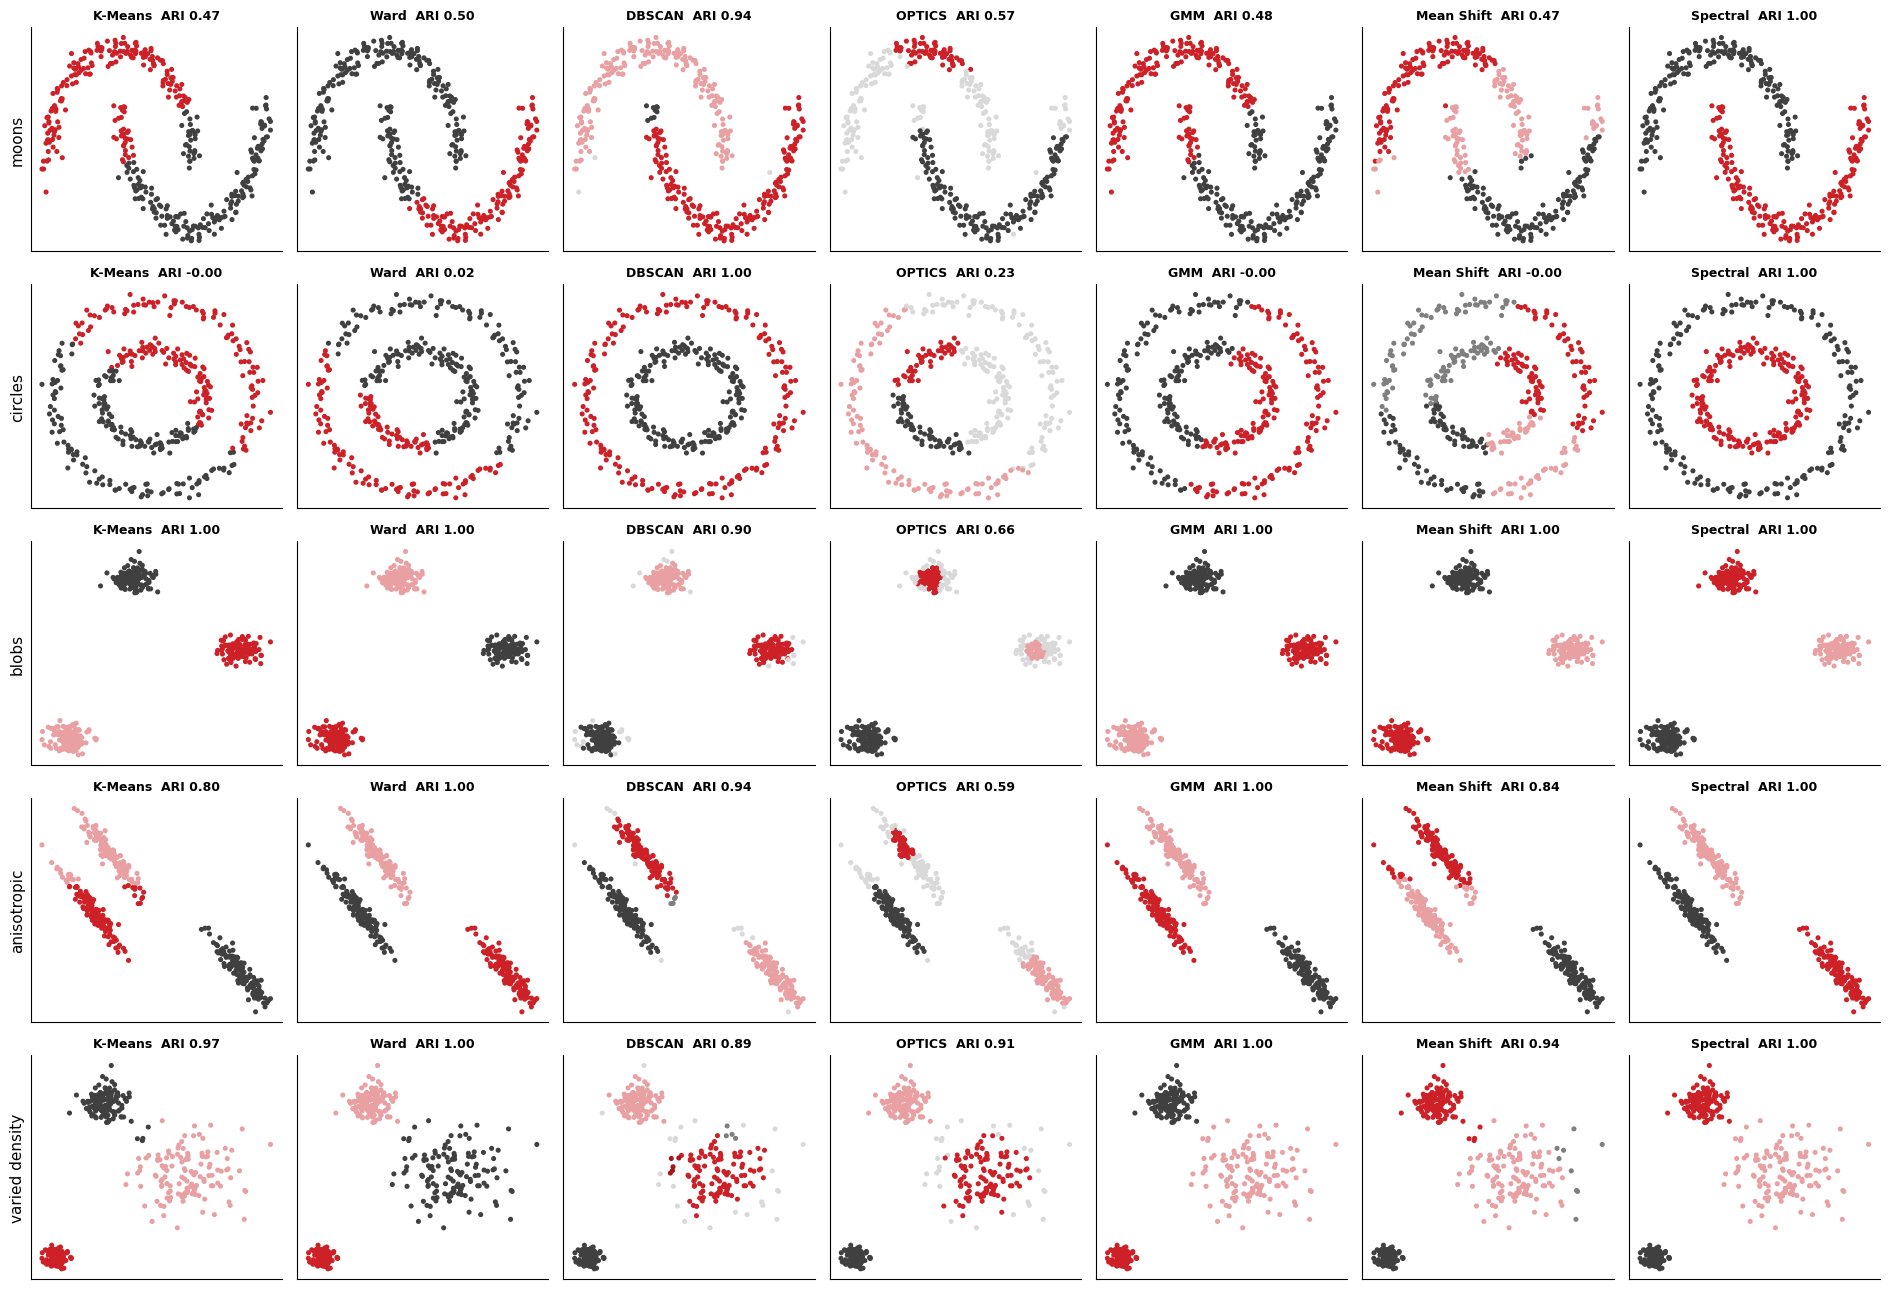

In [17]:
#Run the Seven Algorithms on the Five Datasets: Gallery of Results
def run_algorithms(X, k):
    eps, _ = knee_eps(X, k=5)
    return {"K-Means": KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X),
            "Ward": AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X),
            "DBSCAN": DBSCAN(eps=eps, min_samples=5).fit_predict(X),
            "OPTICS": OPTICS(min_samples=10, xi=0.05, min_cluster_size=0.1).fit_predict(X),
            "GMM": GaussianMixture(n_components=k, covariance_type="full", n_init=3, max_iter=300, random_state=RANDOM_STATE).fit(X).predict(X),
            "Mean Shift": MeanShift(bandwidth=estimate_bandwidth(X, quantile=0.2)).fit_predict(X),
            "Spectral": spectral(X, k)}

bench, store = [], {}
for name, (X_, y_) in datasets.items():
    for algo, labels in run_algorithms(X_, K_TRUE[name]).items():
        store[(name, algo)] = labels
        bench.append({"dataset": name, "algorithm": algo, **cluster_scores(X_, labels, y_)})
bench = pd.DataFrame(bench)

algos = list(bench["algorithm"].unique())
fig, axes = plt.subplots(5, 7, figsize=(19, 13))
cols_ = np.array([DARK, RED, SOFT, GRAY, "#A8141A", "#B07A7C", "#6B6B6B", "#E9A0A3"])
for i, name in enumerate(datasets):
    X_, y_ = datasets[name]
    for j, algo in enumerate(algos):
        l = store[(name, algo)]
        axes[i, j].scatter(X_[:, 0], X_[:, 1], c=[cols_[v % 8] if v >= 0 else "#D9D9D9" for v in l], s=7)
        axes[i, j].set_xticks([]); axes[i, j].set_yticks([])
        axes[i, j].set_title(f"{algo}  ARI {adjusted_rand_score(y_, l):.2f}", fontsize=9)
        if j == 0:
            axes[i, j].set_ylabel(name, fontsize=11)
plt.tight_layout(); plt.show()

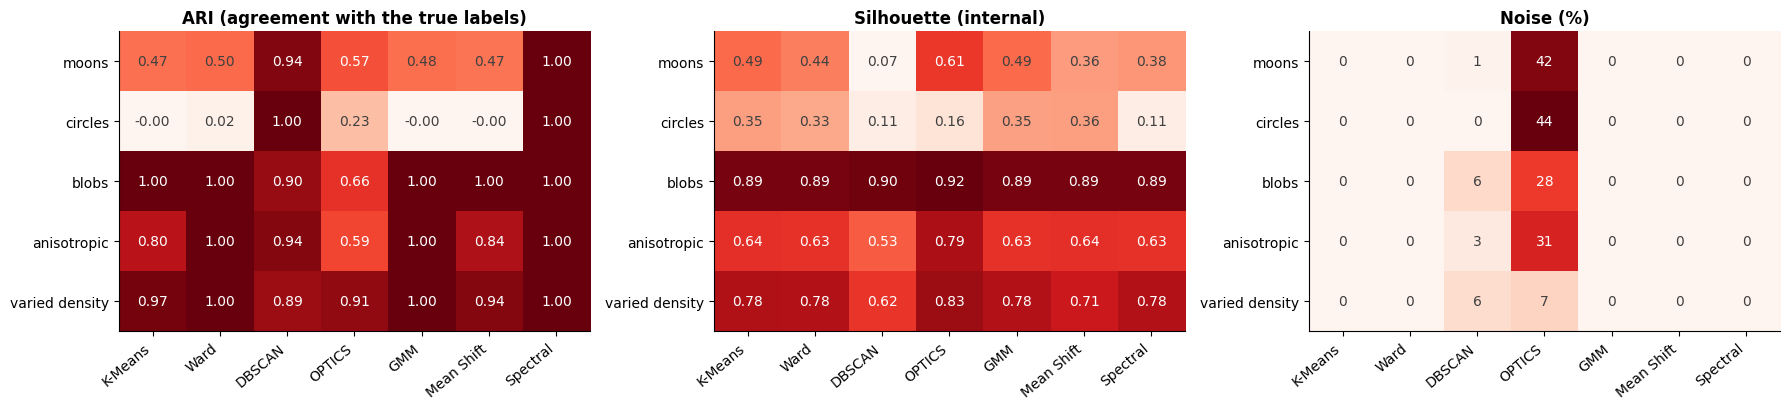

best by ARI                 best by silhouette                 
                 algorithm  ARI silhouette          algorithm   ARI silhouette
dataset                                                                       
anisotropic           Ward  1.0       0.63             OPTICS  0.59       0.79
blobs              K-Means  1.0       0.89             OPTICS  0.66       0.92
circles             DBSCAN  1.0       0.11         Mean Shift -0.00       0.36
moons             Spectral  1.0       0.38             OPTICS  0.57       0.61
varied density        Ward  1.0       0.78             OPTICS  0.91       0.83

In [18]:
#Benchmark Heat Maps: ARI ( External ) and Silhouette ( Internal ) – The Best Internal Score Is Not Always the Right Clustering
fig, axes = plt.subplots(1, 3, figsize=(18, 4.2))
for ax, col, title, fmt in [(axes[0], "ARI", "ARI (agreement with the true labels)", "{:.2f}"), (axes[1], "silhouette", "Silhouette (internal)", "{:.2f}"), (axes[2], "noise %", "Noise (%)", "{:.0f}")]:
    piv = bench.pivot(index="dataset", columns="algorithm", values=col)[algos].loc[list(datasets)]
    ax.imshow(piv.to_numpy(), cmap="Reds", aspect="auto"); ax.grid(False)
    ax.set_xticks(range(len(algos))); ax.set_xticklabels(algos, rotation=40, ha="right"); ax.set_yticks(range(len(datasets))); ax.set_yticklabels(list(datasets)); ax.set_title(title); annotate_heatmap(ax, piv.to_numpy(), fmt)
plt.tight_layout(); plt.show()
best_ari = bench.loc[bench.groupby("dataset")["ARI"].idxmax(), ["dataset", "algorithm", "ARI", "silhouette"]].set_index("dataset")
best_sil = bench.loc[bench.groupby("dataset")["silhouette"].idxmax(), ["dataset", "algorithm", "ARI", "silhouette"]].set_index("dataset")
display(pd.concat({"best by ARI": best_ari, "best by silhouette": best_sil}, axis=1).round(2))

**K-Means, Ward and GMM** win on convex blobs; **DBSCAN, Spectral** (and *single* linkage) win on **moons and circles**. Notice that the **silhouette** can prefer a *wrong* partition (e.g. OPTICS or Mean Shift): it is blind to shape on non-convex data and it is inflated when noise points are excluded. Internal metrics assume **compact** clusters.

### **10. Real Data: Handwritten Digits (64 Dimensions)**

Here the **labels exist** (10 digits) but are **not used** by the algorithms. After matching clusters to classes (Hungarian algorithm), the **generic classification metrics** become available: **confusion matrix**, **accuracy**, and – for soft clusterings – **ROC curves**.

In [19]:
#Cluster the Digits ( 4 Algorithms ) and Compare Internal and External Metrics
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA

dig = load_digits()
Xd, yd = dig.data / 16.0, dig.target
Xd_pca = PCA(n_components=20, random_state=RANDOM_STATE).fit_transform(Xd)
print("digits:", Xd.shape, "| variance kept by the 20 principal components used by the GMM:", round(float(PCA(n_components=20, random_state=RANDOM_STATE).fit(Xd).explained_variance_ratio_.sum()), 3))

gmm_d = GaussianMixture(n_components=10, covariance_type="diag", n_init=3, max_iter=300, random_state=RANDOM_STATE).fit(Xd_pca)
algos_d = {"K-Means": KMeans(n_clusters=10, n_init=10, random_state=RANDOM_STATE).fit_predict(Xd),
           "Ward": AgglomerativeClustering(n_clusters=10, linkage="ward").fit_predict(Xd),
           "GMM (PCA-20, diag)": gmm_d.predict(Xd_pca),
           "Spectral": spectral(Xd, 10),
           "DBSCAN": DBSCAN(eps=knee_eps(Xd, k=5)[0], min_samples=5).fit_predict(Xd)}
rows = []
for name, l in algos_d.items():
    matched, _ = match_clusters(yd, l)
    rows.append({"algorithm": name, **cluster_scores(Xd, l, yd), "accuracy (matched)": float((matched == yd).mean())})
dig_res = pd.DataFrame(rows).set_index("algorithm")
display(dig_res[["clusters", "noise %", "silhouette", "Davies-Bouldin", "ARI", "NMI", "V-measure", "purity", "accuracy (matched)"]].round(3))

digits: (1797, 64) | variance kept by the 20 principal components used by the GMM: 0.894


,clusters,noise %,silhouette,Davies-Bouldin,ARI,NMI,V-measure,purity,accuracy (matched)
algorithm,,,,,,,,,
K-Means,10,0.000,0.182,1.921,0.667,0.739,0.739,0.794,0.794
Ward,10,0.000,0.178,1.889,0.794,0.868,0.868,0.862,0.840
"GMM (PCA-20, diag)",10,0.000,0.178,1.833,0.619,0.744,0.744,0.732,0.714
Spectral,10,0.000,0.182,1.798,0.755,0.853,0.853,0.823,0.808
DBSCAN,1,1.614,NaN,NaN,0.000,0.005,0.005,0.105,0.101


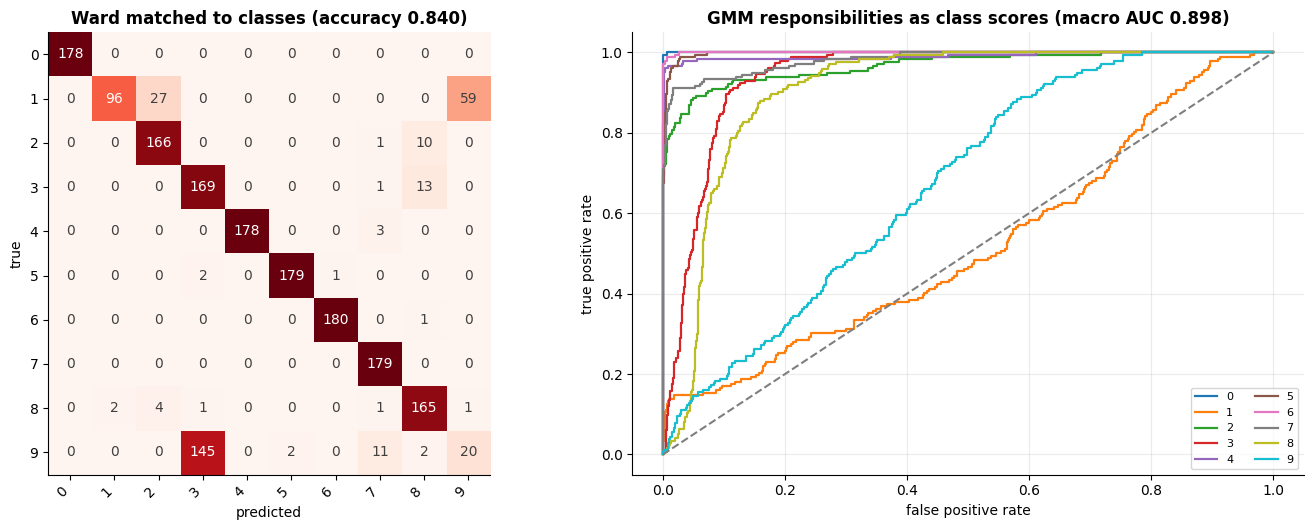

GMM after matching: accuracy 0.714


In [20]:
#Confusion Matrix of the Best Hard Clustering ( Ward after Matching ) and ROC of the Soft Clustering ( GMM Responsibilities )
labels_best = algos_d["Ward"]
matched, mapping = match_clusters(yd, labels_best)
cm = confusion_matrix(yd, matched, labels=list(range(10)))

resp_d = gmm_d.predict_proba(Xd_pca)
mapped_gmm = match_clusters(yd, algos_d["GMM (PCA-20, diag)"])[1]                              # cluster -> class
resp_cls = np.zeros_like(resp_d)
for cluster, cls_ in mapped_gmm.items():
    resp_cls[:, cls_] = resp_d[:, cluster]
pred_gmm = resp_cls.argmax(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.4))
plot_confusion(cm, [str(d) for d in range(10)], axes[0], f"Ward matched to classes (accuracy {np.mean(matched == yd):.3f})")
cmap = plt.get_cmap("tab10")
for c in range(10):
    f, t, _ = roc_curve((yd == c).astype(int), resp_cls[:, c]); axes[1].plot(f, t, color=cmap(c), lw=1.6, label=str(c))
axes[1].plot([0, 1], [0, 1], color=GRAY, ls="--"); axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate"); axes[1].legend(ncol=2, fontsize=8, loc="lower right")
axes[1].set_title(f"GMM responsibilities as class scores (macro AUC {roc_auc_score(yd, resp_cls, multi_class='ovr'):.3f})")
plt.tight_layout(); plt.show()
print(f"GMM after matching: accuracy {np.mean(pred_gmm == yd):.3f}")

DBSCAN, which shone on 2-D shapes, **struggles in 64 dimensions** (the *curse of dimensionality* makes distances similar and densities uniform): it finds a single cluster. **Ward**, **Spectral** and **K-Means** reach 0.79–0.84 accuracy; the GMM with diagonal covariances on 20 principal components is the weakest (0.71).

### **11. Clustering for Outlier Detection**

Points that **do not belong to any cluster** are **outliers**. We inject 30 **uniform outliers** (5 %) into 3 blobs and compare detectors. This is a **binary** problem, so the generic metrics apply: **confusion matrix** (flags), **ROC / PR** (scores).

* **DBSCAN / OPTICS:** noise label (−1); score = distance to the nearest **core point** / **reachability**
* **LOF:** local density relative to the neighbours · **GMM:** low log-likelihood · **k-NN distance:** distance to the 10th neighbour

In [21]:
#Data with Injected Outliers and the Five Detectors ( Flags and Scores )
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from scipy.spatial import cKDTree

rng = np.random.default_rng(RANDOM_STATE)
Xin, _ = make_blobs(570, centers=3, cluster_std=0.7, random_state=RANDOM_STATE)
lo_, hi_ = Xin.min(axis=0) - 2, Xin.max(axis=0) + 2
X_out = np.vstack([Xin, rng.uniform(lo_, hi_, size=(30, 2))])
y_out = np.r_[np.zeros(570), np.ones(30)].astype(int)

eps_o, _ = knee_eps(X_out, k=5)
db = DBSCAN(eps=eps_o, min_samples=5).fit(X_out)
cores = X_out[db.core_sample_indices_]
score_db = cKDTree(cores).query(X_out)[0]                                                    # distance to the nearest core point
op = OPTICS(min_samples=10, xi=0.05, min_cluster_size=0.1).fit(X_out)
reach_o = np.where(np.isinf(op.reachability_), np.nanmax(op.reachability_[np.isfinite(op.reachability_)]) * 2, op.reachability_)
lof = LocalOutlierFactor(n_neighbors=20).fit(X_out)
gmm_o = GaussianMixture(n_components=3, n_init=3, max_iter=300, random_state=RANDOM_STATE).fit(X_out)
knn_score = NearestNeighbors(n_neighbors=11).fit(X_out).kneighbors(X_out)[0][:, -1]

contam = 30 / 600
top5 = lambda s: (s >= np.quantile(s, 1 - contam)).astype(int)                                # flag the top 5% (known contamination)
detectors = {"DBSCAN": (score_db, (db.labels_ == -1).astype(int)), "OPTICS": (reach_o, (op.labels_ == -1).astype(int)), "LOF": (-lof.negative_outlier_factor_, top5(-lof.negative_outlier_factor_)),
             "GMM log-likelihood": (-gmm_o.score_samples(X_out), top5(-gmm_o.score_samples(X_out))), "k-NN distance": (knn_score, top5(knn_score))}
rows = []
for name, (sc_, flag) in detectors.items():
    rows.append({"detector": name, "ROC AUC": roc_auc_score(y_out, sc_), "PR AUC": average_precision_score(y_out, sc_), "flagged": int(flag.sum()),
                 "precision": precision_score(y_out, flag, zero_division=0), "recall": recall_score(y_out, flag), "F1": f1_score(y_out, flag)})
out_df = pd.DataFrame(rows).set_index("detector")
display(out_df.round(3))

,ROC AUC,PR AUC,flagged,precision,recall,F1
detector,,,,,,
DBSCAN,0.965,0.929,32,0.844,0.900,0.871
OPTICS,0.972,0.804,198,0.146,0.967,0.254
LOF,0.977,0.939,30,0.900,0.900,0.900
GMM log-likelihood,0.970,0.886,30,0.800,0.800,0.800
k-NN distance,0.978,0.944,30,0.900,0.900,0.900


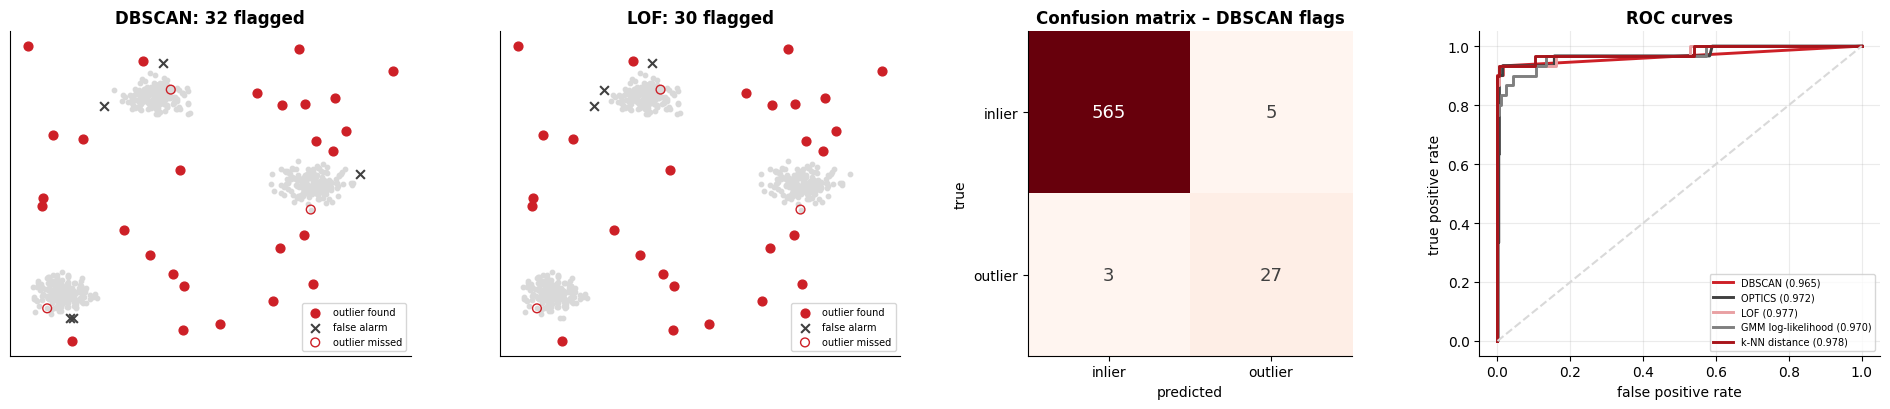

In [22]:
#Outlier Detection: Flags on the Data, Confusion Matrix of DBSCAN and ROC / PR Curves of All the Detectors
fig, axes = plt.subplots(1, 4, figsize=(19, 4.2))
for ax, name in zip(axes[:2], ["DBSCAN", "LOF"]):
    flag = detectors[name][1]
    ax.scatter(*X_out[flag == 0].T, s=10, color=LIGHT); ax.scatter(*X_out[(flag == 1) & (y_out == 1)].T, s=40, color=RED, label="outlier found"); ax.scatter(*X_out[(flag == 1) & (y_out == 0)].T, s=40, marker="x", color=DARK, label="false alarm")
    ax.scatter(*X_out[(flag == 0) & (y_out == 1)].T, s=40, facecolor="none", edgecolor=RED, label="outlier missed"); ax.set_title(f"{name}: {int(flag.sum())} flagged"); ax.legend(fontsize=7); ax.set_xticks([]); ax.set_yticks([])
plot_confusion(confusion_matrix(y_out, detectors["DBSCAN"][1]), ["inlier", "outlier"], axes[2], "Confusion matrix – DBSCAN flags")
for (name, (sc_, _)), color in zip(detectors.items(), [RED, DARK, SOFT, GRAY, "#A8141A"]):
    f, t, _ = roc_curve(y_out, sc_); axes[3].plot(f, t, color=color, lw=2.1, label=f"{name} ({roc_auc_score(y_out, sc_):.3f})")
axes[3].plot([0, 1], [0, 1], color=LIGHT, ls="--"); axes[3].set_xlabel("false positive rate"); axes[3].set_ylabel("true positive rate"); axes[3].set_title("ROC curves"); axes[3].legend(fontsize=7, loc="lower right")
plt.tight_layout(); plt.show()

Some injected outliers fall **inside** the clusters, so no detector can find them (recall < 1 is expected). The **score-based** view (ROC / PR) is **threshold-free**; the **flags** of DBSCAN/OPTICS depend on `eps` / ξ.

### **12. Summary**

| | **K-Means** | **Hierarchical** | **DBSCAN** | **OPTICS** | **GMM** | **Spectral** |
|---|---|---|---|---|---|---|
| Specific metrics | inertia, silhouette, elbow | cophenetic corr., dendrogram | k-distance, core/border/noise | reachability plot | log-likelihood, BIC/AIC, uncertainty | eigengap |
| Main risk | assumes spherical, needs *k* | O(n²) memory | one density, `eps`, high dimension | slower, parameters | local optima, covariance choice | cost, graph choice |
| Best for | compact groups | small data, taxonomy | arbitrary shapes + noise | varied densities | overlapping / elliptical | non-convex shapes |

* **No clustering is universally best:** look at the **geometry**, then validate with **internal** metrics (without labels) and, when possible, **external** ones
* With labels available, **ARI/NMI** and the **matched confusion matrix** quantify the agreement; without labels, use **stability** and domain knowledge